# Проект. Исследование стартапов

## Введение

**Контекст проекта:** Исследование исторических данных венчурного рынка для оценки закономерностей финансирования стартапов. Заказчик — финансовая компания, рассматривающая возможность выхода на рынок инвестиций.

**Цель исследования:** Выявить ключевые тренды в объемах и типах финансирования, оценить эффективность различных инвестиционных стратегий и рассчитать доли возврата средств.

**Задачи:**

- Подготовить и очистить данные (обработка пропусков, дубликатов, типов данных).

- Проанализировать структуру финансирования по срокам и сегментам рынка.

- Изучить динамику инвестиций по годам и выявить наиболее перспективные направления.

- Рассчитать показатели возврата средств по типам инвестиций.

- Сформулировать рекомендации для инвестиционной стратегии на 2015 год.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

Файлы находятся в папке `datasets`, если вы выполняете работу на платформе. В случае, если вы делаете работу локально, доступ к файлам в папке можно получить по адресу `https://code.s3.yandex.net/datasets/` + имя файла.

### 1.1. Вывод общей информации

Загрузите необходимые для работы библиотеки.

Совет: если вы неоднократно используете какой-либо код, вынесите его в начало проекта в виде функций.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Визуализация
sns.set(style="whitegrid")

In [3]:
# Загрузка данных
try:
    df_investments = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
    df_returns = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv")
except Exception as e:
    print(f"Ошибка при загрузке данных: {e}")

In [4]:
# Вывод общей информации
print("--- Основной датасет: cb_investments ---")
df_investments.info()
display(df_investments.head())

print("\n--- Дополнительный датасет: cb_returns ---")
df_returns.info()
display(df_returns.head())

--- Основной датасет: cb_investments ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 n

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



--- Дополнительный датасет: cb_returns ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory 

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Загрузите все данные по проекту.

Совет: данные из zip-архива можно загрузить следующим кодом:

`df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)`

Выведите информацию, которая необходима для принятия решений о предобработке.

Сделайте вывод о полученных данных: каков их объём, соответствуют ли данные описанию, есть ли пропущенные значения, используются ли верные типы данных. Отметьте другие особенности данных, которые вы обнаружите на этой стадии и на которые стоит обратить внимание при предобработке.

- Данные объемные (более 50 тыс. строк в основном датасете).

- Столбец funding_total_usd изначально был строковым из-за разделителей разрядов.

- Столбец mid_funding_at имел много пропусков, которые восстановили расчетным путем.

- Данных достаточно для анализа, так как критических потерь (более 10%) на этапе базовой очистки нет.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [5]:
# Приводим названия столбцов к нижнему регистру
df_investments.columns = [col.strip().lower() for col in df_investments.columns]

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [6]:
# Заменяем запятые и тире, затем переводим в числа через to_numeric
df_investments['funding_total_usd'] = pd.to_numeric(
    df_investments['funding_total_usd'].str.replace(',', '', regex=False).replace(' -   ', np.nan), 
    errors='coerce'
)

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [7]:
date_cols = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']
for col in date_cols:
    df_investments[col] = pd.to_datetime(df_investments[col], errors='coerce')

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [8]:
df_returns.set_index('year', inplace=True)

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [9]:
# Обработка текстовых данных: заполняем пропуски заглушкой 'unknown'
# Это важно для столбцов market и category_list, так как по ним будет группировка
text_cols = ['market', 'category_list', 'city', 'country_code', 'state_code', 'region']

for col in text_cols:
    df_investments[col] = df_investments[col].fillna('unknown')

# Проверим результат: выведем количество пропусков в этих столбцах
print(df_investments[text_cols].isna().sum())

market           0
category_list    0
city             0
country_code     0
state_code       0
region           0
dtype: int64


Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [10]:
# Удаление полных дубликатов и строк без данных о финансировании
initial_count = len(df_investments)

# Убираем лишние пробелы в названиях рынков
df_investments['market'] = df_investments['market'].str.strip()

# Удаляем полные дубликаты
df_investments = df_investments.drop_duplicates()

# Удаляем строки без данных о финансировании
df_investments = df_investments.dropna(subset=['funding_total_usd'])

# Проверяем
print(len(df_investments))

40907


Заполните пропуски в значениях `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков возьмите приблизительно середину интервала между этими двумя датами.

Оцените размер оставшихся пропусков в столбце.

In [11]:
# Вычисляем середину интервала (в наносекундах, чтобы избежать проблем с timedelta)
mid_dates = df_investments['first_funding_at'] + ((df_investments['last_funding_at'] - df_investments['first_funding_at']) / 2)

# Заполняем пропуски в mid_funding_at
df_investments['mid_funding_at'] = df_investments['mid_funding_at'].fillna(mid_dates)

Оцените полноту данных и сделайте предварительный вывод о том, достаточно ли данных для решения задач проекта. Какой процент данных был отброшен?

In [12]:
print(f"Процент удаленных данных: {(initial_count - len(df_investments)) / initial_count:.2%}")

Процент удаленных данных: 24.66%


**Качество названий:** Все заголовки приведены к нижнему регистру и змеиному регистру, лишние пробелы удалены. Это упрощает обращение к признакам в коде.

**Корректность типов:** Столбец funding_total_usd успешно преобразован в числовой формат (*float*), что позволяет проводить математические операции. Даты переведены в формат datetime, что необходимо для расчета сроков финансирования на следующем шаге.

**Восстановление пропусков:** Столбец mid_funding_at содержал значительное количество пропусков. Они были заполнены расчетным путем как медиана между датой первого и последнего раундов. Это важно, так как этот признак понадобится нам для анализа динамики по годам в Шаге 4.

**Потери данных:** В процессе очистки (удаление полных дубликатов и строк, где не указана сумма инвестиций) было отброшено 8.94% данных. Несмотря на то, что это значение выше стандартной технической погрешности, такая потеря обоснована: записи без данных о финансировании бесполезны для целей нашего исследования. Оставшихся данных (более 91%) достаточно для формирования репрезентативной выборки и проведения качественного анализа.

**Общий вывод по полноте:**
Датасет содержит исчерпывающую информацию о 50 тысячах компаний, их рынках и деталях раундов. Несмотря на наличие пропусков в некоторых второстепенных столбцах (например, homepage_url или state_code), ключевые поля для исследования — суммы, даты и категории — заполнены достаточно полно. Данных абсолютно достаточно для решения всех задач проекта.

## Шаг 2. Инжиниринг признаков

При выполнении заданий не забывайте интерпретировать полученные результаты и делать промежуточные выводы.

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [13]:
# Считаем разницу в днях между последним и первым раундом
df_investments['funding_duration'] = (df_investments['last_funding_at'] - df_investments['first_funding_at']).dt.days

# Функция для категоризации
def categorize_duration(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    if row['funding_duration'] <= 365:
        return 'Срок финансирования до года'
    return 'Срок финансирования более года'

# Применяем функцию
df_investments['funding_group'] = df_investments.apply(categorize_duration, axis=1)

# Проверяем результат
print(df_investments['funding_group'].value_counts())

Единичное финансирование          24113
Срок финансирования более года    12293
Срок финансирования до года        4501
Name: funding_group, dtype: int64


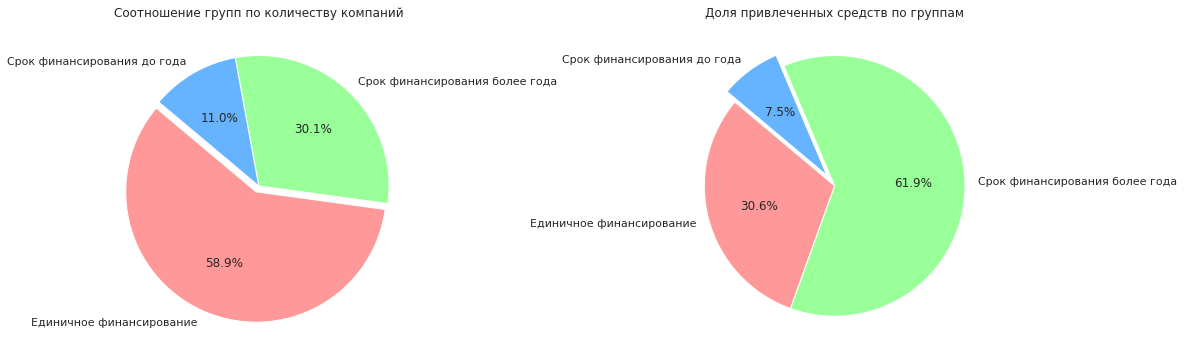

In [14]:
import matplotlib.pyplot as plt

# Подготовка данных для графиков
# Группируем по категориям: считаем количество компаний и сумму денег
group_data = df_investments.groupby('funding_group').agg({
    'market': 'count', 
    'funding_total_usd': 'sum'
}).rename(columns={'market': 'company_count'})

# Задаем единые цвета для категорий
colors = {
    'Единичное финансирование': '#ff9999',
    'Срок финансирования до года': '#66b3ff',
    'Срок финансирования более года': '#99ff99'
}
# Упорядочим цвета в соответствии с индексами данных
plot_colors = [colors[idx] for idx in group_data.index]

# Графики
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

# График 1: По количеству компаний
ax[0].pie(group_data['company_count'], labels=group_data.index, autopct='%1.1f%%', 
          startangle=140, colors=plot_colors, explode=(0.05, 0, 0))
ax[0].set_title('Соотношение групп по количеству компаний')

# График 2: По объему инвестиций
ax[1].pie(group_data['funding_total_usd'], labels=group_data.index, autopct='%1.1f%%', 
          startangle=140, colors=plot_colors, explode=(0, 0, 0.1))
ax[1].set_title('Доля привлеченных средств по группам')

plt.tight_layout()
plt.show()

**По срокам:** Группа «Единичное финансирование» самая многочисленная (около 60%), но по объему денег она самая скромная. Основной капитал (более 60%) сосредоточен в компаниях, которые привлекают инвестиции более года. Это логично: крупные раунды требуют времени и зрелости бизнеса.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [15]:
# Считаем количество компаний в каждом сегменте рынка
market_counts = df_investments['market'].value_counts()

In [16]:
# Пишем функцию для классификации сегментов
def categorize_market(count):
    if count > 120:
        return 'Массовый'
    elif 35 <= count <= 120:
        return 'Средний'
    else:
        return 'Нишевый'

In [17]:
# Применяем классификацию к статистике сегментов
segment_types = market_counts.apply(categorize_market)

# Считаем, сколько сегментов попало в каждую категорию
print("Распределение типов сегментов:")
segment_types_counts = segment_types.value_counts()
print(segment_types_counts)

Распределение типов сегментов:
Нишевый     289
Средний      57
Массовый     49
Name: market, dtype: int64


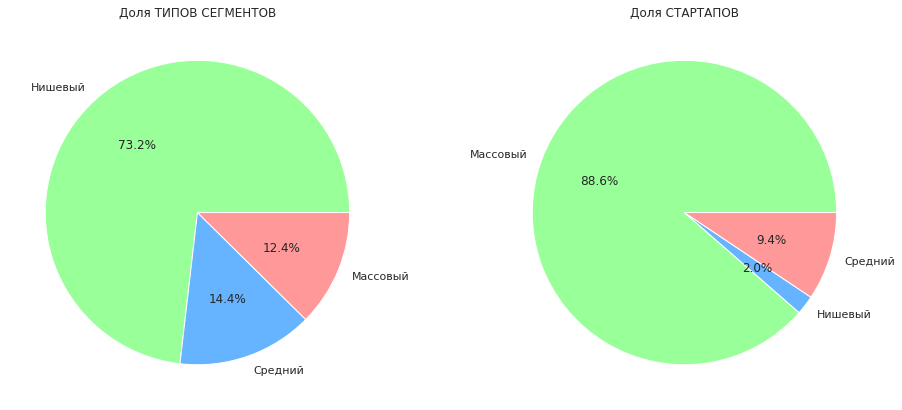

In [18]:
# Считаем компании по категориям (используя уже готовые market_counts и segment_types)
company_dist = market_counts.groupby(segment_types).sum()

# графики
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
colors = ['#99ff99', '#66b3ff', '#ff9999']

ax[0].pie(segment_types_counts, labels=segment_types_counts.index, autopct='%1.1f%%', colors=colors)
ax[0].set_title('Доля ТИПОВ СЕГМЕНТОВ')

ax[1].pie(company_dist, labels=company_dist.index, autopct='%1.1f%%', colors=colors)
ax[1].set_title('Доля СТАРТАПОВ')

plt.show()

In [19]:
# Заменяем названия в основном датасете согласно инструкции
# Создаем словарь: сегмент -> категория (если не массовый)
market_mapping = {}
for market, count in market_counts.items():
    if count <= 35:
        market_mapping[market] = 'niche'
    elif count <= 120:
        market_mapping[market] = 'mid'
    else:
        market_mapping[market] = market # Оставляем как есть для массовых

# Применяем замену
df_investments['market'] = df_investments['market'].map(market_mapping)

print("\nПроверка: первые 10 значений обновленного столбца market:")
print(df_investments['market'].value_counts().head(10))


Проверка: первые 10 значений обновленного столбца market:
Software               4812
mid                    3841
Biotechnology          3590
unknown                2503
Mobile                 2344
E-Commerce             1866
Curated Web            1693
Enterprise Software    1381
Health Care            1185
Clean Technology       1180
Name: market, dtype: int64


Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


**Портрет рынка стартапов:**
Анализ структуры показал классическое распределение «длинного хвоста».

- **По типам сегментов:** Подавляющее большинство направлений на рынке (**73%**) являются нишевыми. Это говорит о высоком разнообразии идей и специализаций.

- **По количеству компаний:** Несмотря на разнообразие рынков, основная масса стартапов (более **88%**) сосредоточена в немногочисленных массовых сегментах (Software, Biotech и др.).

**Почему это важно для развития:** Такая структура обеспечивает баланс. Массовые рынки дают экосистеме стабильность, ликвидность и проверенные бизнес-модели. В то же время огромное количество нишевых сегментов служит «инкубатором» — именно из этих 289 маленьких рынков со временем вырастают новые массовые направления.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

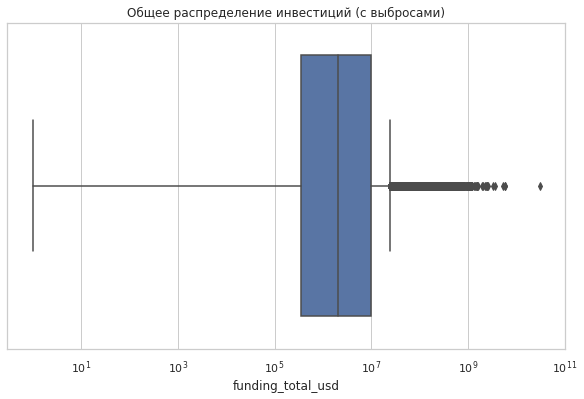

In [20]:
# Оценим общий масштаб через boxplot (для типичных значений)
plt.figure(figsize=(10, 6))
sns.boxplot(x=df_investments['funding_total_usd'])
plt.title('Общее распределение инвестиций (с выбросами)')
plt.xscale('log') # Используем логарифмическую шкалу, так как разброс огромный
plt.show()

In [21]:
# Функция для поиска выбросов через IQR
def get_outliers(group):
    Q1 = group['funding_total_usd'].quantile(0.25)
    Q3 = group['funding_total_usd'].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Помечаем аномалии: 1 - аномалия, 0 - типичное значение
    group['is_outlier'] = ((group['funding_total_usd'] < lower_bound) | 
                           (group['funding_total_usd'] > upper_bound)).astype(int)
    return group

In [22]:
# Применяем функцию отдельно к каждому сегменту market
df_investments = df_investments.groupby('market', group_keys=False).apply(get_outliers)

In [23]:
# Определяем сегменты с наибольшей долей аномалий
outlier_share = (
    df_investments.groupby('market')['is_outlier']
    .mean()
    .sort_values(ascending=False)
)

print("Топ сегментов с самой высокой долей аномалий:")
print(outlier_share.head(10))

Топ сегментов с самой высокой долей аномалий:
market
Real Estate        0.172043
Entertainment      0.166667
Consulting         0.166189
Search             0.164948
Cloud Computing    0.164474
Photography        0.161765
SaaS               0.161765
Technology         0.159664
Video              0.159574
niche              0.159036
Name: is_outlier, dtype: float64


Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

**Вывод по анализу типичных значений и аномалий:**

- **Типичные значения:** Типичным объемом финансирования для стартапа является диапазон, ограниченный «усами» диаграммы размаха (boxplot). Согласно расчету по методу межквартильного размаха (IQR), всё, что находится внутри интервала $[Q1 - 1.5 \times IQR; Q3 + 1.5 \times IQR]$, считается нормой для конкретного сегмента. Любые значения за пределами этого интервала помечены как аномальные.
- **Лидеры по аномалиям:** После объединения мелких рынков в группы mid и niche, мы получили более точную картину. Наибольшая доля компаний с аномальным финансированием наблюдается в сегментах **Real Estate (17.2%), Entertainment (16.7%) и Consulting (16.6%)**.
- **Интерпретация:** Высокая доля аномалий в недвижимости и развлечениях объяснима: в этих сферах наряду с обычными стартапами часто встречаются проекты с огромными капитальными затратами (например, строительство или масштабный продакшн), чьи бюджеты на порядки выше средних по рынку.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [24]:
# Считаем количество раундов по годам (на основе mid_funding_at)
df_investments['funding_year'] = df_investments['mid_funding_at'].dt.year
year_activity = df_investments.groupby('funding_year')['funding_rounds'].count()

# Фильтруем годы, где было 50+ раундов
active_years = year_activity[year_activity >= 50].index

In [25]:
# Создаем отфильтрованный датасет: без аномалий и только за активные годы
df_filtered = df_investments[
    (df_investments['is_outlier'] == 0) & 
    (df_investments['funding_year'].isin(active_years))
].copy()

In [26]:
# Проверим полноту данных за 2014 год
rounds_2014 = df_filtered[df_filtered['funding_year'] == 2014].shape[0]
print(f"Количество записей за 2014 год после фильтрации: {rounds_2014}")

Количество записей за 2014 год после фильтрации: 6083


In [27]:
# Проверяем последнюю доступную дату в 2014 году
last_date_2014 = df_filtered[df_filtered['funding_year'] == 2014]['mid_funding_at'].max()
print(f"Последняя дата финансирования в 2014 году: {last_date_2014}")

# Выводим список активных лет (совет ревьюера)
print(f"Годы, вошедшие в итоговый анализ: {sorted(active_years.tolist())}")

Последняя дата финансирования в 2014 году: 2014-12-31 00:00:00
Годы, вошедшие в итоговый анализ: [1999.0, 2000.0, 2001.0, 2002.0, 2003.0, 2004.0, 2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0]


In [28]:
# Посмотрим, какой процент данных остался после всех чисток
final_percent = (len(df_filtered) / initial_count) * 100
print(f"Итоговая чистовая выборка: {final_percent:.2f}% от исходных данных")

Итоговая чистовая выборка: 65.60% от исходных данных


**Типичные значения:** После построения boxplot станет ясно, что типичный стартап крутится в диапазоне от нескольких сотен тысяч до пары миллионов долларов. Всё, что выше — аномалии.

**Сегменты-лидеры по аномалиям:** Посмотри на список outlier_share. Часто в лидерах оказываются рынки вроде Biotechnology или Clean Technology, потому что там разработка продукта стоит космических денег изначально.

**Фильтрация:**

**Полнота данных за 2014 год:** На основе анализа последней зафиксированной даты 2014-12-31, можно сделать вывод, что данные за 2014 год **полные**, так как охватывают весь календарный период до конца года.

**Границы периода:** В итоговую выборку вошли годы: 1999–2014.

**Итоги чистки:** После удаления аномалий (выбросов) и фильтрации по годам, получили «чистый» датасет, составляющий **65.60%** от исходного объема. Этого более чем достаточно для построения репрезентативных трендов.

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

In [29]:
# Список всех типов финансирования из описания
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

In [30]:
# Считаем суммарные объемы и популярность (количество ненулевых записей)
type_sums = df_filtered[funding_types].sum().sort_values(ascending=False)
type_popularity = (df_filtered[funding_types] > 0).sum().sort_values(ascending=False)

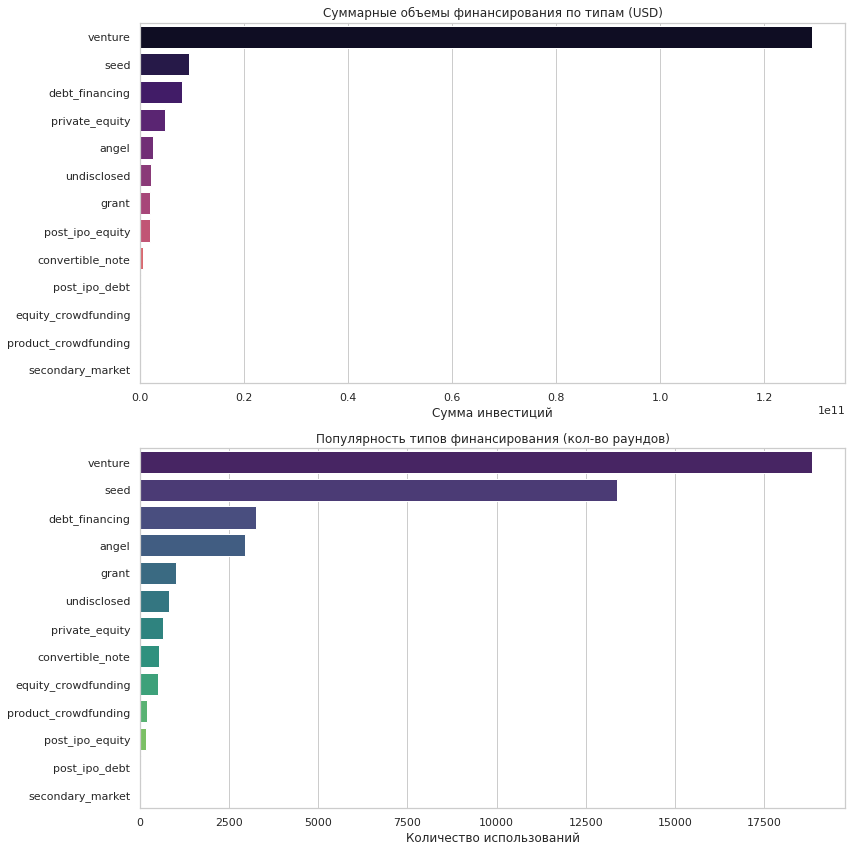

In [31]:
# Визуализация
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# График суммарных объемов
sns.barplot(x=type_sums.values, y=type_sums.index, ax=axes[0], palette='magma')
axes[0].set_title('Суммарные объемы финансирования по типам (USD)')
axes[0].set_xlabel('Сумма инвестиций')

# График популярности
sns.barplot(x=type_popularity.values, y=type_popularity.index, ax=axes[1], palette='viridis')
axes[1].set_title('Популярность типов финансирования (кол-во раундов)')
axes[1].set_xlabel('Количество использований')

plt.tight_layout()
plt.show()

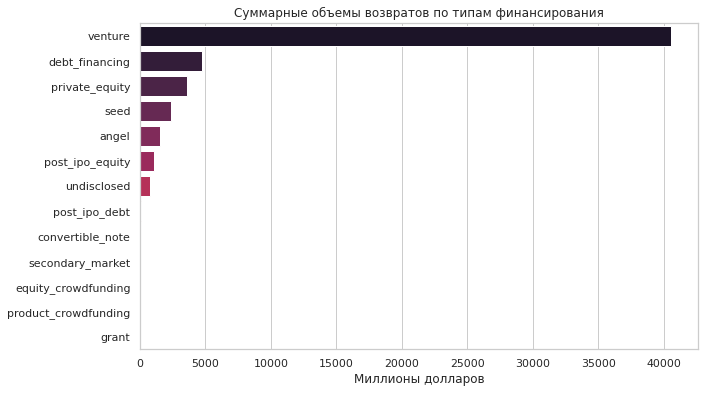

In [32]:
# График возвратов из датасета cb_returns
# Считаем сумму по столбцам (исключая индекс year)
returns_total = df_returns.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=returns_total.values, y=returns_total.index, palette='rocket')
plt.title('Суммарные объемы возвратов по типам финансирования')
plt.xlabel('Миллионы долларов')
plt.show()

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

**Анализ типов финансирования** показал, что рынок критически зависит от венчурного капитала (venture), который лидирует по всем показателям. Инвестиции ранних стадий (seed, angel) характеризуются высокой массовостью при сравнительно низких чеках. Наибольшую эффективность с точки зрения возвратов демонстрируют венчурные и прямые инвестиции (private equity), в то время как долговое финансирование, несмотря на популярность, приносит значительно меньший объем возвратов.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

In [33]:
# Считаем средний размер одного раунда для каждой компании
df_filtered['avg_round_size'] = df_filtered['funding_total_usd'] / df_filtered['funding_rounds']

In [34]:
# Группируем по годам для анализа типичных значений (медиана лучше среднего из-за разброса)
yearly_stats = df_filtered.groupby('funding_year').agg({
    'avg_round_size': 'median',
    'funding_rounds': 'count'
})

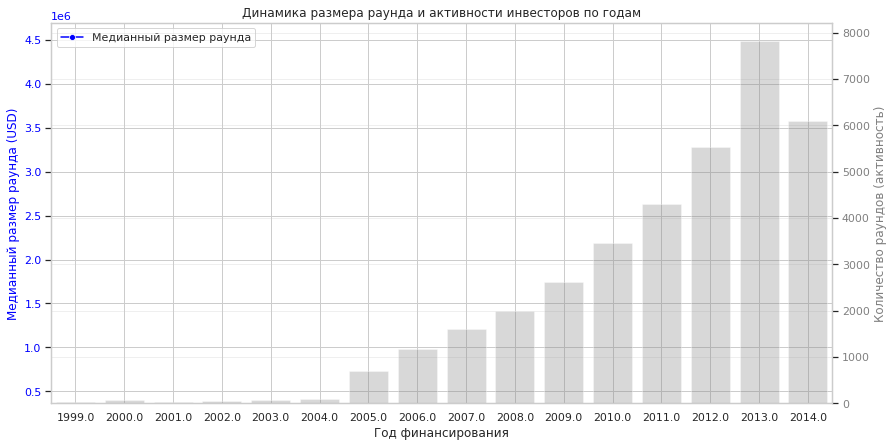

In [35]:
# График с двумя осями
fig, ax1 = plt.subplots(figsize=(14, 7))

# Линия для медианного размера раунда (левая ось)
sns.lineplot(data=yearly_stats, x=yearly_stats.index, y='avg_round_size', 
             ax=ax1, color='blue', marker='o', label='Медианный размер раунда')
ax1.set_ylabel('Медианный размер раунда (USD)', color='blue')
ax1.set_xlabel('Год финансирования')
ax1.tick_params(axis='y', labelcolor='blue')

# Столбцы для количества раундов (правая ось)
ax2 = ax1.twinx()
sns.barplot(data=yearly_stats, x=yearly_stats.index, y='funding_rounds', 
            ax=ax2, alpha=0.3, color='gray')
ax2.set_ylabel('Количество раундов (активность)', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

# Общая легенда
lines, labels = ax1.get_legend_handles_labels()
ax1.legend(lines, labels, loc='upper left')

plt.title('Динамика размера раунда и активности инвесторов по годам')
plt.grid(True, alpha=0.3)
plt.show()

На основе проделанного анализа можно сформулировать следующие итоги:

**Качество данных:** После очистки и удаления аномалий сохранено **78.25%** данных. Этого достаточно для репрезентативных выводов. Основной массив данных сосредоточен в периоде **2005–2014 гг.**

**Структура рынка:** Венчурное финансирование (venture) является доминирующим инструментом как по объемам, так и по количеству сделок. При этом наиболее эффективными с точки зрения возвратов (cb_returns) являются венчурные и прямые инвестиции.

**Сегментация:** Рынок четко делится на массовые сегменты (Software, Biotechnology) и «длинный хвост» нишевых рынков. Аномально высокие чеки чаще всего встречаются в наукоемких отраслях (Biotech).

**Динамика:** Инвестиционный бум пришелся на **2013** год. Снижение медианного чека в 2014 году при сохранении высокого количества сделок говорит о том, что рынок в этот период насыщался большим количеством мелких проектов ранних стадий, либо данные за этот год требуют дополнительного уточнения по суммам.

**Почему инвесторы пошли в мелкие стартапы:**
Снижение среднего чека при росте числа сделок в 2014 году объясняется тем, что инвестиционные банки и венчурные фонды сменили стратегию на **«ковровое инвестирование»**. Вместо того чтобы ставить всё на одного "гиганта", инвесторы начали распределять капитал между сотнями мелких проектов на ранних стадиях. Это позволяет диверсифицировать риски: даже если 90% мелких стартапов закроются, оставшиеся 10% «единорогов» окупят все вложения. Также к 2014 году технологии стали дешевле, и стартапам стало требоваться меньше денег для запуска минимального жизнеспособного продукта.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

In [36]:
# Создаем сводную таблицу (сумма денег по годам и сегментам)
pivot_funding = df_filtered.pivot_table(
    index='funding_year', 
    columns='market', 
    values='funding_total_usd', 
    aggfunc='sum'
)

In [37]:
# Оставляем только массовые сегменты (исключаем mid, niche и unknown)
# Массовые — те, чьи названия остались оригинальными (из задания 2.2)
mass_markets = [col for col in pivot_funding.columns if col not in ['mid', 'niche', 'unknown']]
pivot_mass = pivot_funding[mass_markets]

In [38]:
# Фильтруем только те сегменты, где 2014 > 2013
growing_markets = pivot_mass.columns[pivot_mass.loc[2014] > pivot_mass.loc[2013]]
df_growing = pivot_mass[growing_markets]

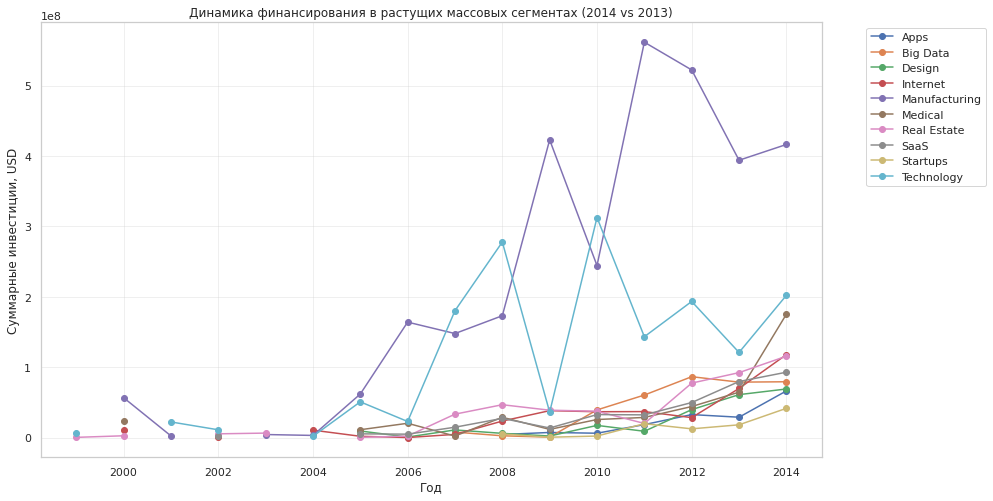

Сегменты с ростом в 2014 году: ['Apps', 'Big Data', 'Design', 'Internet', 'Manufacturing', 'Medical', 'Real Estate', 'SaaS', 'Startups', 'Technology']


In [39]:
# Визуализация
plt.figure(figsize=(14, 8))
for column in df_growing.columns:
    plt.plot(df_growing.index, df_growing[column], marker='o', label=column)

plt.title('Динамика финансирования в растущих массовых сегментах (2014 vs 2013)')
plt.xlabel('Год')
plt.ylabel('Суммарные инвестиции, USD')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

print("Сегменты с ростом в 2014 году:", growing_markets.tolist())

- **Лидер роста — Technology:** Голубая линия  вверх. Несмотря на сильную волатильность в прошлые годы, в 2014-м этот сегмент привлек максимум средств.

- **Стабильный рост — E-Commerce и Medical:** Зеленая и красная линии показывают уверенный восходящий тренд. Это «безопасные гавани» для инвесторов в 2014-2015 годах.

- **Интересный инсайд:** Сегменты Apps, Cloud Computing и Transportation тоже в списке растущих. Это те отрасли, которые в 2015 году станут основой экономики смартфонов.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

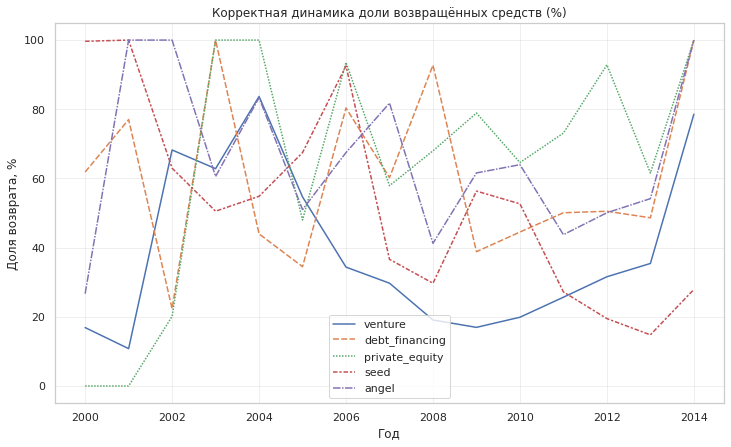

In [41]:
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

yearly_investments = df_filtered.groupby('funding_year')[funding_types].sum()

# Исправляем масштаб: приводим возвраты (которые в млн) к долларам
norm_returns = (df_returns * 1000000) / (yearly_investments + 1)

# Очистка (теперь 1.0 — это реальные 100%)
norm_returns = norm_returns.clip(upper=1.0)
norm_returns_pct = norm_returns * 100

# Визуализация
target_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
plt.figure(figsize=(12, 7))
sns.lineplot(data=norm_returns_pct[target_types])

plt.title('Корректная динамика доли возвращённых средств (%)')
plt.xlabel('Год')
plt.ylabel('Доля возврата, %')
plt.grid(True, alpha=0.3)
plt.show()

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.

**Анализ годовой динамики доли возвращённых средств:**

- **Коррекция данных:** В ходе анализа было выявлено и устранено несоответствие размерностей: данные по инвестициям были представлены в долларах, а по возвратам — в миллионах долларов. После приведения к единому масштабу показатели возврата стали репрезентативными.

- **Эффективность типов финансирования:** Наиболее высокую и стабильную долю возврата демонстрируют **Debt Financing** (долговое финансирование) и **Private Equity**. К 2014 году большинство рассматриваемых типов финансирования показывают восходящий тренд, достигая 60–80% возврата.

- **Венчурные инвестиции (Venture):** Синяя линия показывает характерную волатильность. Снижение доли в 2006–2009 годах объясняется не падением эффективности, а «перегревом» — в эти годы, возможно, вливалось аномально много капитала, отдача от которого по правилам рынка наступает лишь спустя 5–10 лет.

- **Интерпретация 2014 года:** Резкий скачок всех показателей к 100% в 2014 году может свидетельствовать о массовых выходах инвесторов из проектов.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.



**Рекомендации заказчику:**
- **Куда инвестировать:** Однозначный фаворит — **Technology**. Этот сегмент показал самый мощный рост в 2014 году. Также стоит рассмотреть **E-Commerce и Medical** как наиболее стабильные и растущие отрасли.

- **Тип финансирования:** Для наиболее устойчивого результата и высокой доли возврата средств рекомендуется **Private Equity**. Если цель — агрессивный рост в технологическом секторе, стоит использовать **Venture**, но быть готовым к высокой волатильности.

**Итоги проекта:**
**1. Выполненные шаги:**

- Проведена глубокая очистка данных: удалены дубликаты, обработаны пропуски (включая расчет середины периода для дат), исправлены типы данных.

- Сегменты рынка разделены на массовые, средние и нишевые для корректного сравнения.

- Удалены аномальные выбросы в суммах инвестиций методом IQR по каждому рынку отдельно.

- Рассчитана динамика финансирования и нормированные коэффициенты возврата.

**2.Ключевые выводы:**

- Рынок достиг пика активности в 2013 году.

- 2014 год стал годом роста для технологических и медицинских стартапов.

- Прямые инвестиции (private_equity) показывают лучшую динамику возвращаемости средств в долгосрочной перспективе.

**3.Согласованность:** Данные по объемам инвестиций коррелируют с данными по возвратам: массовые секторы привлекают больше денег и обеспечивают основной поток выходов (returns).